# 01 · SSVEP 脑电信号与预处理

本笔记回答三个问题：

1. SSVEP 脑电信号**长什么样**（基频、谐波、多通道、噪声）；
2. 怎么用 **FFT 频谱**直接"看见"被试注视的刺激频率；
3. 分类前标准的**预处理**流程：带通滤波、50Hz 陷波、按触发分段（扣除视觉延迟）、归一化。

> 配套工程代码见 `ssvep/preprocess.py`。图中标签用英文以避免字体问题，正文为中文讲解。

In [1]:
from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd().parent))  # 让 notebook 能 import 上级目录的 ssvep 包
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.unicode_minus': False})
np.set_printoptions(precision=3, suppress=True)
print('环境就绪，工程路径已加入 sys.path')

环境就绪，工程路径已加入 sys.path


## 一、SSVEP 现象

当眼睛注视一个以固定频率 $f$（例如 10 Hz）闪烁的光源时，大脑视觉皮层
（后脑勺**枕区** O1 / Oz / O2 电极附近）的脑电会出现：

- 与刺激**同频**的成分 $f$（基频）；
- 整数倍频率 $2f, 3f, \ldots$（**谐波**）。

8 个闪烁目标对应 8 个频率，所以分类任务的本质就是：

> **判断这段脑电信号里，最强的周期成分对应哪个刺激频率。**

下面先构造一段"干净"的模拟信号：10 Hz 基频 + 2、3 次谐波。

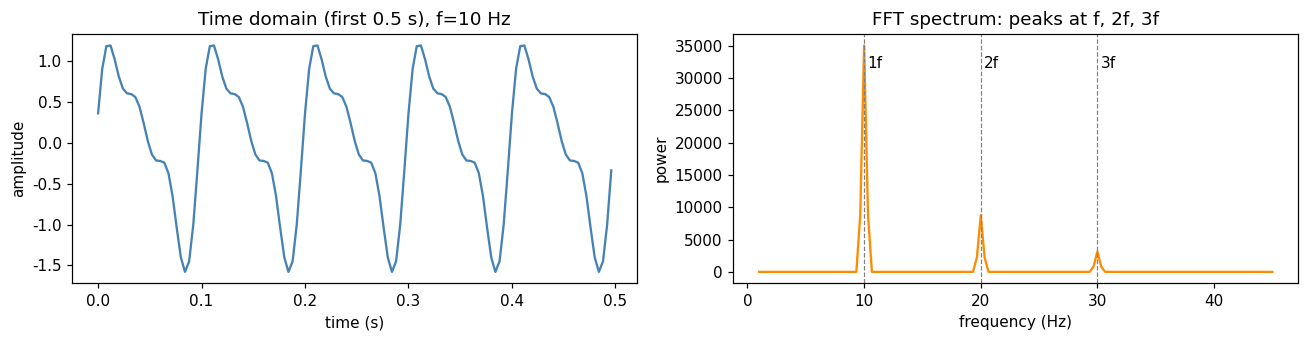

In [2]:
fs, duration, f_stim = 250, 3.0, 10.0
t = np.arange(int(fs*duration)) / fs
clean = (1.0*np.sin(2*np.pi*f_stim*t)
         + 0.5*np.sin(2*np.pi*2*f_stim*t + 0.3)
         + 0.3*np.sin(2*np.pi*3*f_stim*t + 0.8))

def spectrum(x, fs):
    x = x - x.mean()
    n = len(x)
    sp = np.abs(np.fft.rfft(x*np.hanning(n)))**2
    fr = np.fft.rfftfreq(n, 1/fs)
    return fr, sp

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
n_show = int(0.5*fs)
axes[0].plot(t[:n_show], clean[:n_show], color='steelblue')
axes[0].set(xlabel='time (s)', ylabel='amplitude',
            title='Time domain (first 0.5 s), f=10 Hz')
fr, sp = spectrum(clean, fs)
band = (fr >= 1) & (fr <= 45)
axes[1].plot(fr[band], sp[band], color='darkorange')
for h in (1, 2, 3):
    axes[1].axvline(h*f_stim, ls='--', color='gray', lw=0.8)
    axes[1].text(h*f_stim+0.3, sp[band].max()*0.9, f'{h}f')
axes[1].set(xlabel='frequency (Hz)', ylabel='power',
            title='FFT spectrum: peaks at f, 2f, 3f')
plt.tight_layout(); plt.show()

左图时域上 10 Hz 的周期振荡；右图频谱上在 **10 / 20 / 30 Hz** 出现三个尖峰，
分别对应基频与谐波。真实脑电没有这么干净——下面加高斯噪声。

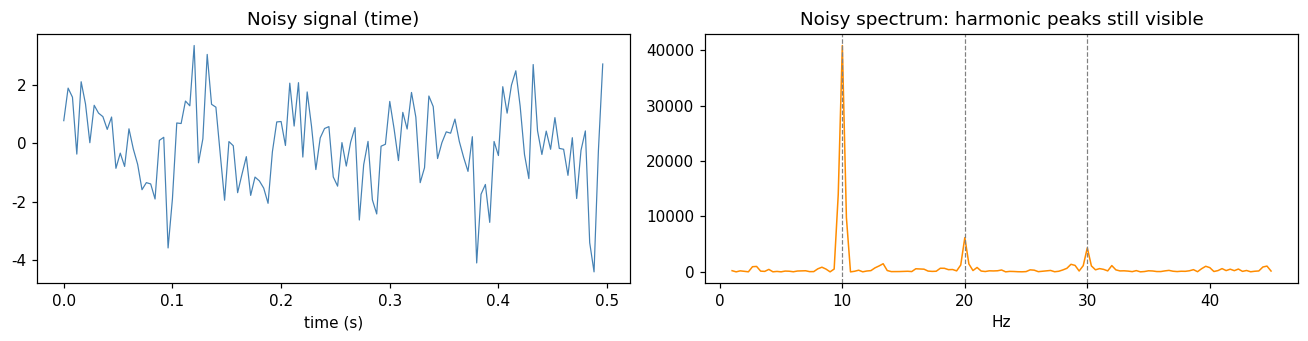

In [3]:
rng = np.random.default_rng(1)
noisy = clean + 1.2*rng.normal(size=clean.shape)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].plot(t[:n_show], noisy[:n_show], color='steelblue', lw=0.8)
axes[0].set(title='Noisy signal (time)', xlabel='time (s)')
fr, sp = spectrum(noisy, fs)
axes[1].plot(fr[band], sp[band], color='darkorange', lw=1)
for h in (1, 2, 3):
    axes[1].axvline(h*f_stim, ls='--', color='gray', lw=0.8)
axes[1].set(title='Noisy spectrum: harmonic peaks still visible', xlabel='Hz')
plt.tight_layout(); plt.show()

## 多通道：同一组源信号的不同线性混合

电极帽上有多个通道（比赛常见 8~9 个枕/顶区通道）。可以把每个通道理解为
基频/谐波"源信号"的某种线性混合，再叠加噪声：

$$X_{C\times T} = M_{C\times 3}\,S_{3\times T} + N$$

不同通道里 f、2f、3f 的强弱不同——这正是后面 CCA/TRCA 要利用的空间信息。

X shape = (9, 750)  -> (channels, samples)


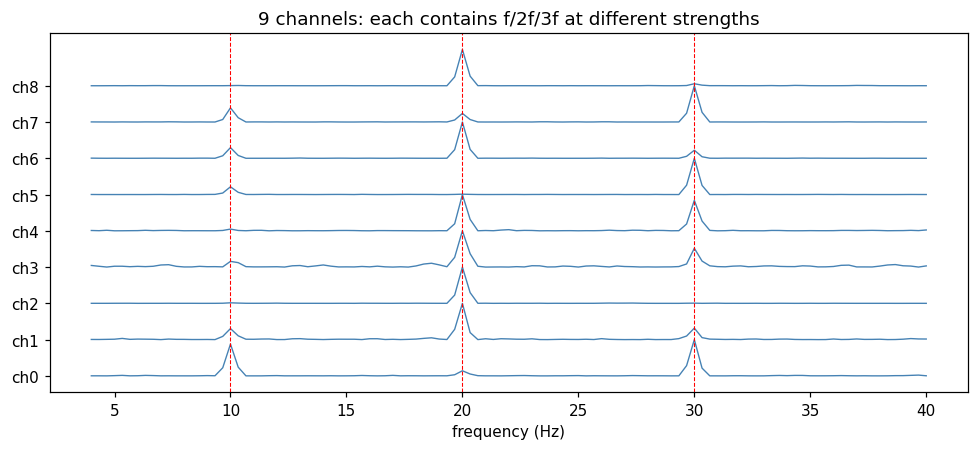

In [4]:
n_ch = 9
sources = np.vstack([np.sin(2*np.pi*h*f_stim*t + [0, 0.3, 0.8][h-1])
                     for h in (1, 2, 3)])
mixing = rng.normal(size=(n_ch, 3))
X = mixing @ sources + 0.8*rng.normal(size=(n_ch, len(t)))
print('X shape =', X.shape, ' -> (channels, samples)')

fig, ax = plt.subplots(figsize=(9, 4.2))
for ch in range(n_ch):
    fr, sp = spectrum(X[ch], fs)
    b = (fr >= 4) & (fr <= 40)
    ax.plot(fr[b], sp[b]/sp[b].max() + ch, color='steelblue', lw=0.9)
ax.set_yticks(range(n_ch))
ax.set_yticklabels([f'ch{i}' for i in range(n_ch)])
for h in (1, 2, 3):
    ax.axvline(h*f_stim, ls='--', color='red', lw=0.7)
ax.set(xlabel='frequency (Hz)',
       title='9 channels: each contains f/2f/3f at different strengths')
plt.tight_layout(); plt.show()

## 二、预处理

### 2.1 带通滤波

SSVEP 的有用信息一般在 6~80 Hz。带通滤波可以去掉低频直流漂移和高频肌电噪声。
工程里使用 `scipy.signal.filtfilt`（正反向各滤一次），**零相位失真**，
不会把信号在时间上推后。

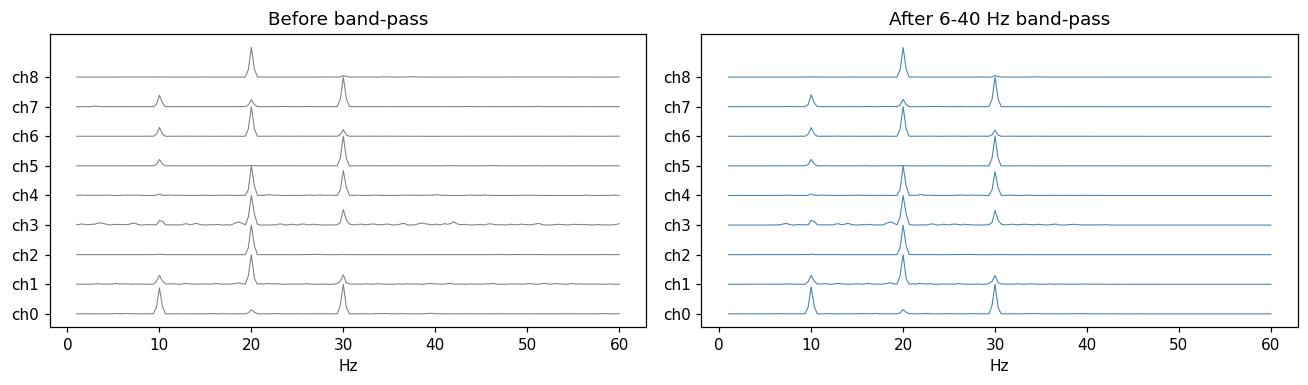

In [5]:
from ssvep.preprocess import bandpass_filter
Xf = bandpass_filter(X, fs, 6.0, 40.0)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ch in range(n_ch):
    fr, sp = spectrum(X[ch], fs); b = (fr >= 1) & (fr <= 60)
    axes[0].plot(fr[b], sp[b]/sp[b].max()+ch, color='gray', lw=0.7)
    fr2, sp2 = spectrum(Xf[ch], fs)
    axes[1].plot(fr[b], sp2[b]/sp2[b].max()+ch, color='steelblue', lw=0.7)
axes[0].set_title('Before band-pass')
axes[1].set_title('After 6-40 Hz band-pass')
for a in axes:
    a.set_yticks(range(n_ch))
    a.set_yticklabels([f'ch{i}' for i in range(n_ch)])
    a.set_xlabel('Hz')
plt.tight_layout(); plt.show()

### 2.2 工频陷波（50 Hz）

市电 50 Hz 及其谐波容易通过电极线混入脑电。用 IIR 陷波器在 50 Hz 处开一个
窄"缺口"，只压制 50 Hz 附近极窄的频段，基本不影响其他频率。

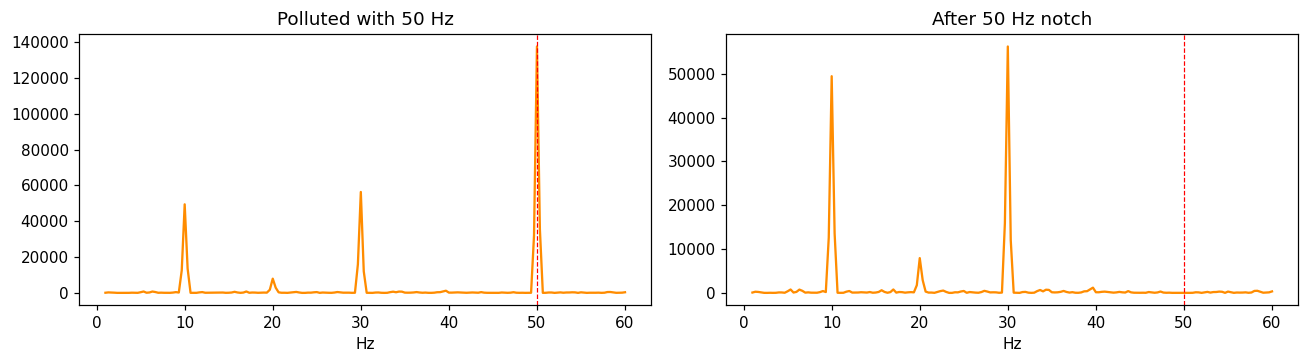

In [6]:
from ssvep.preprocess import notch_filter
line_noise = 2.0*np.sin(2*np.pi*50*t)        # 模拟 50Hz 市电干扰
x_polluted = X[0] + line_noise
x_clean = notch_filter(x_polluted, fs, f0=50.0)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, sig, title in [(axes[0], x_polluted, 'Polluted with 50 Hz'),
                       (axes[1], x_clean, 'After 50 Hz notch')]:
    fr, sp = spectrum(sig, fs); b = (fr >= 1) & (fr <= 60)
    ax.plot(fr[b], sp[b], color='darkorange')
    ax.axvline(50, color='red', ls='--', lw=0.8)
    ax.set(title=title, xlabel='Hz')
plt.tight_layout(); plt.show()

### 2.3 按触发点分段，扣除 0.14 s 视觉延迟

比赛数据可能是**连续记录**，需要按每次刺激开始的触发时刻（trigger）切片。
从屏幕刷新 → 视网膜 → 视觉皮层产生稳定响应约有 **0.14 s 延迟**，且刺激开始
瞬间存在瞬态响应，因此每个片段统一跳过前 0.14 s，再取固定时长窗口。
工程中由 `epoch()` 完成。

epochs shape = (3, 9, 375)  -> (n_trial, channels, samples)


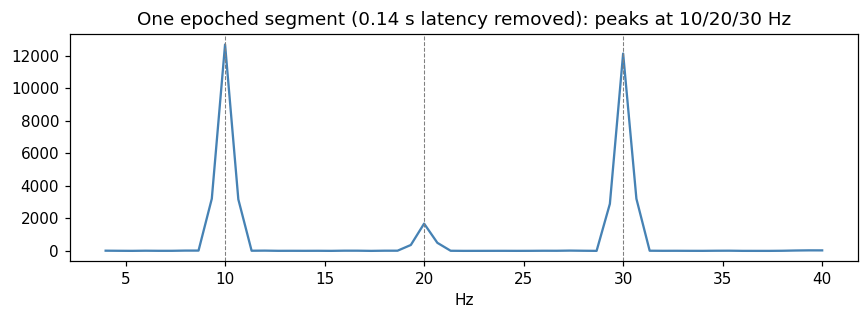

In [7]:
from ssvep.preprocess import epoch
cont = 0.3*rng.normal(size=(9, int(14*fs)))
triggers = [2.0, 6.0, 10.0]
for tg in triggers:
    s = int(tg*fs)
    tt = np.arange(int(2*fs))/fs
    burst = np.vstack([np.sin(2*np.pi*h*10*tt) for h in (1, 2, 3)])
    cont[:, s:s+int(2*fs)] += mixing @ burst

eps = epoch(cont, triggers, fs, offset=0.14, duration=1.5)
print('epochs shape =', eps.shape, ' -> (n_trial, channels, samples)')

fr, sp = spectrum(eps[0, 0], fs)
b = (fr >= 4) & (fr <= 40)
plt.figure(figsize=(8, 3))
plt.plot(fr[b], sp[b], color='steelblue')
for h in (1, 2, 3):
    plt.axvline(10*h, ls='--', color='gray', lw=0.7)
plt.title('One epoched segment (0.14 s latency removed): peaks at 10/20/30 Hz')
plt.xlabel('Hz'); plt.tight_layout(); plt.show()

### 2.4 通道归一化（z-score）

逐通道减去均值、除以标准差，消除各电极阻抗差异带来的幅度尺度差，
使 CCA/TRCA 的相关计算只关注波形形状。

In [8]:
from ssvep.preprocess import zscore
eps_n = zscore(eps, axis=-1)
print('before: global mean=%.3f  std=%.3f' % (eps.mean(), eps.std()))
print('after : global mean=%.3f  std=%.3f' % (eps_n.mean(), eps_n.std()))

before: global mean=-0.005  std=1.175
after : global mean=0.000  std=1.000


## 小结

- SSVEP 的判别信息在频谱上：**基频 f 与谐波 2f、3f 的尖峰**，主要分布在枕区通道。
- 标准预处理流水线：**50 Hz 陷波 → 6~80 Hz 带通 → 按触发分段（扣 0.14 s）→ z-score**。
- 对应工程函数：`notch_filter / bandpass_filter / epoch / zscore`（`ssvep/preprocess.py`）。
- 拿到任何新数据，先画频谱确认峰的位置，再谈分类。

下一笔记：**02 · CCA 典型相关分析**——如何用数学方法自动找到主导频率。